# Análise de Vendas — TechBooks 📊

**Projeto de análise de dados com Python, Pandas, SQLite, Matplotlib e Seaborn.**

## Objetivo do projeto

Este projeto tem como objetivo analisar os dados fictícios de vendas da TechBooks, uma empresa de exemplo que comercializa produtos das categorias Eletrônicos, Roupas e Livros.

Por meio da linguagem Python e de consultas a um banco de dados SQLite, serão explorados os valores das vendas, o faturamento por produto, a distribuição mensal da receita e o desempenho de cada categoria.

A proposta é praticar conceitos de análise e manipulação de dados, utilizar visualizações gráficas para facilitar a interpretação dos resultados e identificar informações que poderiam auxiliar na tomada de decisões de negócio.

**Ferramentas utilizadas:** Python, Pandas, SQLite, Matplotlib e Seaborn.

In [2]:
#1. Conectando ao banco de dados e criando tabela
import sqlite3

conn = sqlite3.connect('dados_vendas.db')
cursor = conn.cursor()

cursor.execute('''
CREATE TABLE IF NOT EXISTS vendas1(
    id_venda INTEGER PRIMARY KEY AUTOINCREMENT,
    data_venda TEXT,
    produto TEXT,
    categoria TEXT,
    valor_venda REAL
)
''')

conn.commit()
print("Tabela 'vendas' criada com sucesso!")

Tabela 'vendas' criada com sucesso!


In [3]:
#2. inserindo registros de vendas

import sqlite3

conn = sqlite3.connect("dados_vendas.db")
cursor = conn.cursor()

# Evita duplicar os registros de exemplo ao executar novamente
cursor.execute("DELETE FROM vendas1")

cursor.executemany("""
    INSERT INTO vendas1
    (data_venda, produto, categoria, valor_venda)
    VALUES (?, ?, ?, ?)
""", [
    ("2026-01-01", "Smartphone", "Eletrônicos", 2500.00),
    ("2026-01-05", "Jaqueta de couro", "Roupas", 350.00),
    ("2026-02-10", "Tablet S10", "Eletrônicos", 1200.00),
    ("2026-03-15", "Box Harry Potter", "Livros", 200.00),
    ("2026-03-20", "Teclado gamer", "Eletrônicos", 300.00),
    ("2026-04-02", "Calça Jeans", "Roupas", 150.00),
    ("2026-05-05", "Fogo & Sangue", "Livros", 150.00),
    ("2026-06-10", "Monitor gamer", "Eletrônicos", 1000.00),
    ("2026-07-20", "Tênis", "Roupas", 600.00),
    ("2026-08-25", "Kindle", "Eletrônicos", 700.00),
    ("2026-09-30", "Box Trono de Vidro", "Livros", 300.00),
    ("2026-10-05", "Bota cano alto", "Roupas", 450.00),
    ("2026-11-15", "Mouse gamer", "Eletrônicos", 200.00),
    ("2026-12-20", "Box Crônicas de Nárnia", "Livros", 350.00),
])

conn.commit()
conn.close()

print("Dados de exemplo inseridos com sucesso!")


Dados de exemplo inseridos com sucesso!


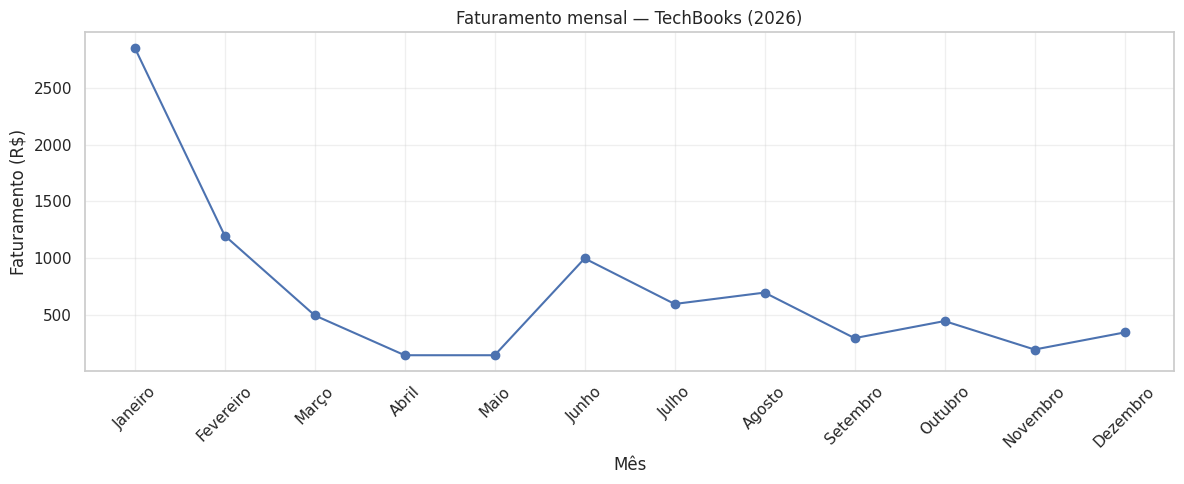

In [7]:
#3. Gráfico de faturamento por mês
import pandas as pd
import matplotlib.pyplot as plt

conn = sqlite3.connect("dados_vendas.db")
df = pd.read_sql_query("SELECT * FROM vendas1", conn)
conn.close()

df["data_venda"] = pd.to_datetime(df["data_venda"])
df["mes"] = df["data_venda"].dt.month

nomes_meses = [
    "Janeiro", "Fevereiro", "Março", "Abril",
    "Maio", "Junho", "Julho", "Agosto",
    "Setembro", "Outubro", "Novembro", "Dezembro"
]

faturamento_mensal = (
    df.groupby("mes")["valor_venda"]
    .sum()
    .reindex(range(1, 13), fill_value=0)
)

plt.figure(figsize=(12, 5))
plt.plot(
    nomes_meses,
    faturamento_mensal.values,
    marker="o"
)

plt.title("Faturamento mensal — TechBooks (2026)")
plt.xlabel("Mês")
plt.ylabel("Faturamento (R$)")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
#4. Filtro booleano - destaque pro produto mais vendido em valor
acima_de_1000 = df[df['total']> 1000]

print(f'Vendas acima de R$1.000: {len(acima_de_1000)} de {len(df)} registros\n')
print(acima_de_1000[['date', 'produto', 'total']]
      .sort_values('total', ascending=False) # organiza os resultados com base na coluna 'total' em ordem decrescente
      .to_string(index=False)) #Converte o DataFrame resultante em uma string para exibição, e index=False garante que o índice do DataFrame não seja impresso, tornando a saída mais limpa.

Vendas acima de R$1.000: 2 de 14 registros

      date    produto  total
2026-01-01 Smartphone 2500.0
2026-02-10 Tablet S10 1200.0


In [ ]:
#6. qual produto trouxe mais dinheiro?
ranking = (df.groupby('produto')['total'].sum().sort_values(ascending=False).reset_index()) #agrupa apenas a coluna produto e soma os valores da coluna total por produto

ranking.columns = ['Produto', 'Faturamento Total'] # renomeia as colunas do DataFrame ranking para 'Produto' e 'Faturamento Total
ranking['Faturamento Total'] = ranking['Faturamento Total'].apply(lambda x: f"R${x:,.2f}") #cada valor na coluna 'Faturamento Total' é formatado como uma string de moeda brasileira

print("\nRanking de faturamento da Loja TechBooks:")
print(ranking.to_string(index=False))


Ranking de faturamento da Loja TechBooks:
               Produto Faturamento Total
            Smartphone        R$2,500.00
            Tablet S10        R$1,200.00
         Monitor gamer        R$1,000.00
                Kindle          R$700.00
                 Tenis          R$600.00
        Bota cano alto          R$450.00
Box Crônicas de Nárnia          R$350.00
      Jaqueta de couro          R$350.00
         Teclado gamer          R$300.00
    Box trono de vidro          R$300.00
      Box Harry potter          R$200.00
           Mouse gamer          R$200.00
        Fogo & Sangue           R$150.00
           Calça Jeans          R$150.00


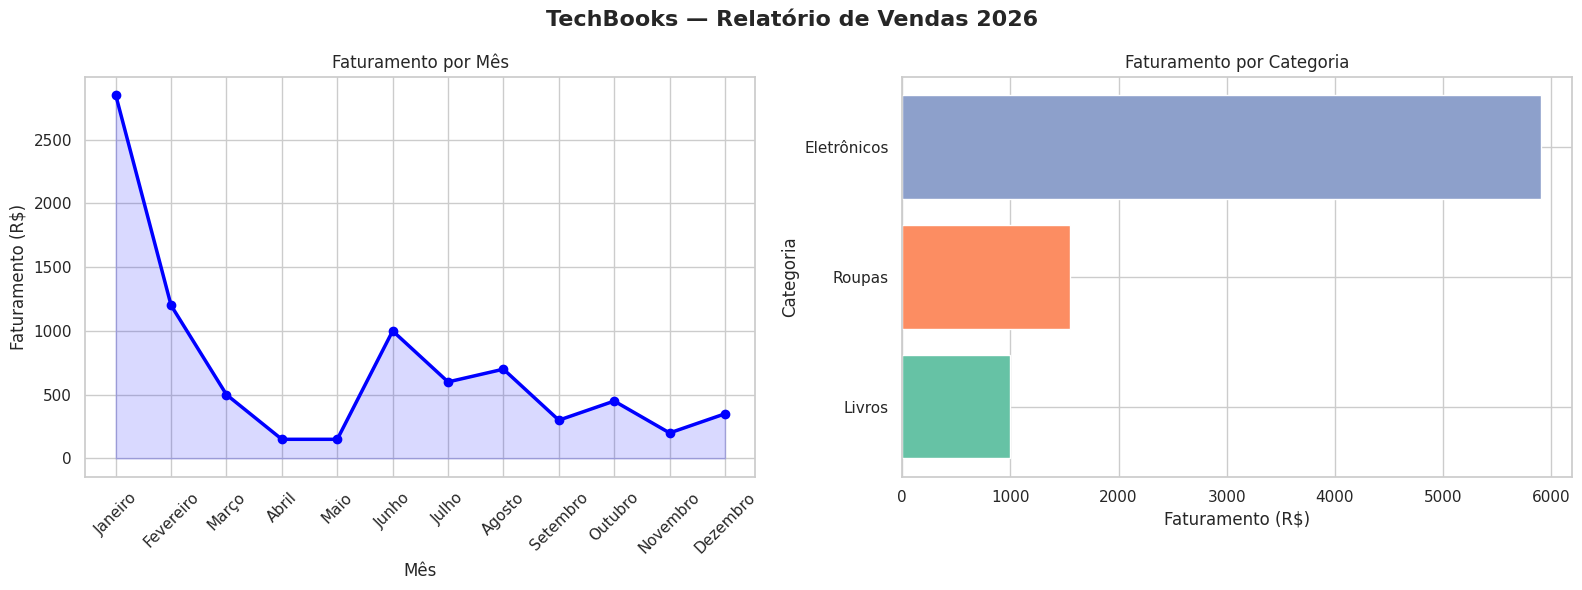

In [6]:
# 6. Criando gráficos

import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

# Ordem correta dos meses do ano
meses_ordem = [
    'Janeiro', 'Fevereiro', 'Março', 'Abril',
    'Maio', 'Junho', 'Julho', 'Agosto',
    'Setembro', 'Outubro', 'Novembro', 'Dezembro'
]

# Criando a coluna 'mes_nome' mapeando os números dos meses existentes para os nomes em português
mapeamento_meses = dict(zip(range(1, 13), meses_ordem))
df['mes_nome'] = df['mes'].map(mapeamento_meses)

# Criando a figura com dois gráficos lado a lado
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

fig.suptitle(
    'TechBooks — Relatório de Vendas 2026',
    fontsize=16,
    fontweight='bold'
)

# Gráfico 1 — Faturamento mensal
fat_mes = (
    df.groupby('mes_nome')['valor_venda']
    .sum()
    .reindex(meses_ordem, fill_value=0)
)

axes[0].plot(
    fat_mes.index,
    fat_mes.values,
    marker='o',
    color='blue',
    linewidth=2.5
)

axes[0].fill_between(
    range(len(fat_mes)),
    fat_mes.values,
    alpha=0.15,
    color='blue'
)

axes[0].set_title('Faturamento por Mês')
axes[0].set_xlabel('Mês')
axes[0].set_ylabel('Faturamento (R$)')
axes[0].tick_params(axis='x', rotation=45)

# Gráfico 2 — Faturamento por categoria (corrigido usando 'valor_venda')
fat_cat = (
    df.groupby('categoria')['valor_venda']
    .sum()
    .sort_values()
)

axes[1].barh(
    fat_cat.index,
    fat_cat.values,
    color=sns.color_palette('Set2', len(fat_cat))
)

axes[1].set_title('Faturamento por Categoria')
axes[1].set_xlabel('Faturamento (R$)')
axes[1].set_ylabel('Categoria')

plt.tight_layout()
plt.show()


## Principais conclusões 📈

A análise dos dados de vendas da TechBooks permitiu identificar os seguintes resultados:

- **Faturamento total:** as 14 vendas registradas somaram R$ 8.450,00 no período analisado.

- **Categoria de destaque:** Eletrônicos apresentou o maior faturamento, totalizando R$ 5.900,00, aproximadamente 69,8% da receita total.

- **Produto com maior valor de venda individual:** o Smartphone registrou a maior venda, no valor de R$ 2.500,00.

- **Distribuição do faturamento:** a análise mensal permite observar como a receita se distribuiu ao longo do ano e identificar os meses com maiores e menores valores.

### Considerações finais

O projeto permitiu praticar a consulta e a organização de dados com SQLite e Pandas, a aplicação de filtros e agrupamentos e a criação de gráficos com Matplotlib e Seaborn.

A experiência reforçou a importância de transformar dados brutos em informações que facilitem a compreensão do desempenho de um negócio. Como próximos passos, a análise poderá ser ampliada com indicadores adicionais e um dashboard interativo no Power BI.

*Observação: os dados utilizados neste projeto são fictícios e foram criados exclusivamente para fins de estudo.*